In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('data_science_job.csv')

In [3]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [4]:
df.isna().mean() * 100

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

In [5]:
cols = [col for col in df.columns if df[col].isna().mean() < 0.05 and df[col].isna().mean() > 0]

In [6]:
cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [7]:
new_df = df[cols]

In [8]:
new_df.head()

,city_development_index,enrolled_university,education_level,experience,training_hours
0,0.920,no_enrollment,Graduate,20.0,36.0
1,0.776,no_enrollment,Graduate,15.0,47.0
2,0.624,Full time course,Graduate,5.0,83.0
3,0.789,NaN,Graduate,0.0,52.0
4,0.767,no_enrollment,Masters,20.0,8.0


In [9]:
new_df.dropna().shape[0]/df.shape[0]

0.8968577095730244

In [10]:
new_df.dropna(inplace= True)

C:\Users\gpava\AppData\Local\Temp\ipykernel_20380\4135980325.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df.dropna(inplace= True)


In [11]:
new_df.shape[0]

17182

In [12]:
df.shape[0]

19158

<Axes: >

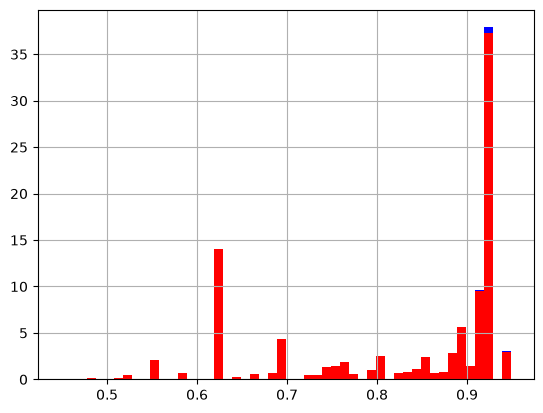

In [13]:
new_df['city_development_index'].hist(bins = 50, color = 'blue', density = True)
df['city_development_index'].hist(bins = 50, color = 'red', alpha = 1, density = True)

<Axes: ylabel='Density'>

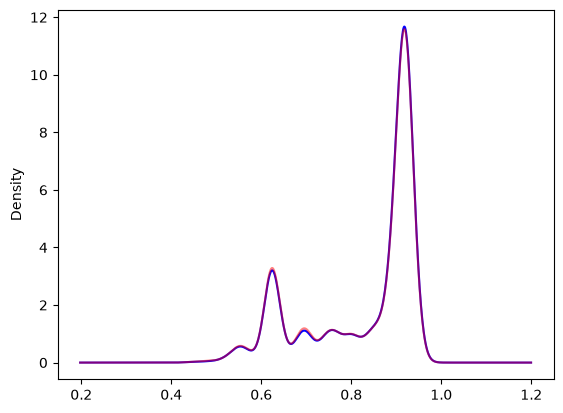

In [14]:
new_df['city_development_index'].plot.density(color = 'blue')
df['city_development_index'].plot.density(color = 'red', alpha = 0.5)

<Axes: >

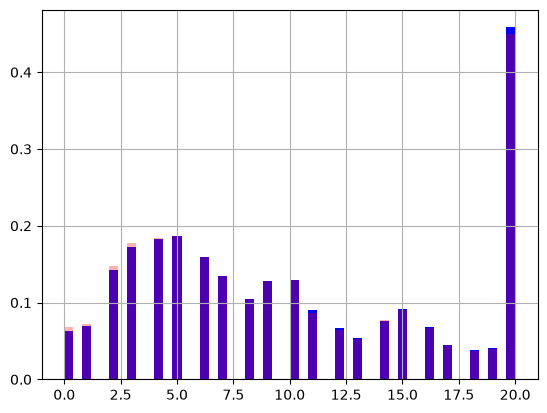

In [15]:
new_df['experience'].hist(bins = 50, color = 'blue', density = True)
df['experience'].hist(bins = 50, color = 'red', alpha = 0.3, density = True)

<Axes: ylabel='Density'>

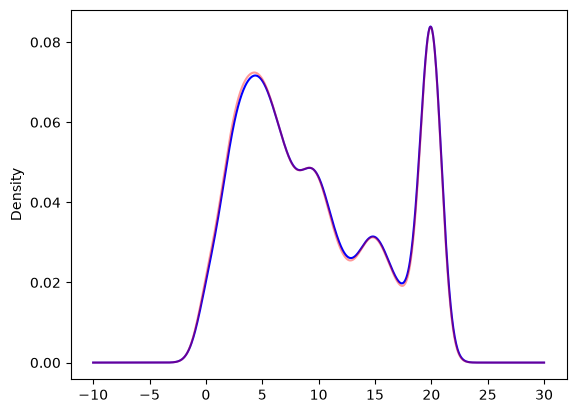

In [16]:
new_df['experience'].plot.density(color = 'blue')
df['experience'].plot.density(color = 'red', alpha = 0.4)

<Axes: >

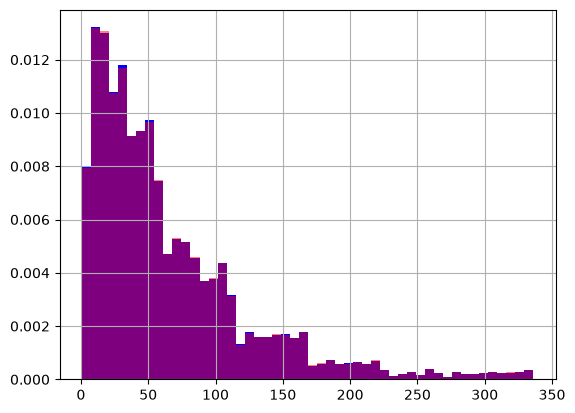

In [17]:
new_df['training_hours'].hist(bins = 50, density = True, color = 'blue')
df['training_hours'].hist(bins = 50, density =True, color = 'red', alpha = 0.5)

<Axes: ylabel='Density'>

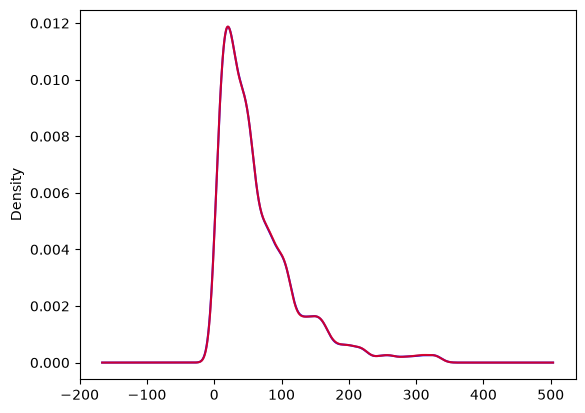

In [18]:
new_df['training_hours'].plot.density(color = 'blue')
df['training_hours'].plot.density(color = 'red', alpha = 0.8)

In [19]:
new_df.head()

,city_development_index,enrolled_university,education_level,experience,training_hours
0,0.920,no_enrollment,Graduate,20.0,36.0
1,0.776,no_enrollment,Graduate,15.0,47.0
2,0.624,Full time course,Graduate,5.0,83.0
4,0.767,no_enrollment,Masters,20.0,8.0
5,0.764,Part time course,Graduate,11.0,24.0


In [20]:
new_df['enrolled_university'].value_counts() / new_df.shape[0]

enrolled_university
no_enrollment       0.735188
Full time course    0.200733
Part time course    0.064079
Name: count, dtype: float64

In [21]:
df['enrolled_university'].value_counts() / df.shape[0]

enrolled_university
no_enrollment       0.721213
Full time course    0.196106
Part time course    0.062533
Name: count, dtype: float64

In [22]:
temp = pd.concat([new_df['enrolled_university'].value_counts() / new_df.shape[0], df['enrolled_university'].value_counts() / df.shape[0]], axis= 1)

In [23]:
temp.columns = ['cca', 'original']

In [24]:
temp

,cca,original
enrolled_university,,
no_enrollment,0.735188,0.721213
Full time course,0.200733,0.196106
Part time course,0.064079,0.062533


In [25]:
temp = pd.concat([df['education_level'].value_counts() / df.shape[0], new_df['education_level'].value_counts() / new_df.shape[0]], axis= 1)

In [26]:
temp.columns = ['original', 'cca']

In [27]:
temp

,original,cca
education_level,,
Graduate,0.605387,0.619835
Masters,0.227633,0.234082
High School,0.105282,0.107380
Phd,0.021610,0.022116
Primary School,0.016077,0.016587
